In [1]:
import pathlib
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

from oso_airfoils.core.colors import default_color_cycle as dcc
from oso_airfoils.geometry.kulfan import Kulfan
matplotlib.rcParams['axes.prop_cycle'] = matplotlib.cycler(color=dcc)

HERE     = pathlib.Path('__file__').parent.resolve()
ORIG_DIR = HERE          # originals/
DAT_DIR  = HERE.parent   # datfiles/


In [3]:
# Each entry: (display name, existing dat path, TEST dat path)
AIRFOILS = [
    # ('afl-du-family1', ORIG_DIR / 'afl-du-family1.dat', ORIG_DIR / 'afl-du-family1_TEST.dat'),
    # ('afl-du-family2', ORIG_DIR / 'afl-du-family2.dat', ORIG_DIR / 'afl-du-family2_TEST.dat'),
    # ('afl-du-family3', ORIG_DIR / 'afl-du-family3.dat', ORIG_DIR / 'afl-du-family3_TEST.dat'),
    # ('afl-du-family4', ORIG_DIR / 'afl-du-family4.dat', ORIG_DIR / 'afl-du-family4_TEST.dat'),
    ('du_91-w2-250',   DAT_DIR  / 'du_91-w2-250.dat',  DAT_DIR  / 'du_91-w2-250_TEST.dat'),
    ('du_93-w-210',    DAT_DIR  / 'du_93-w-210.dat',   DAT_DIR  / 'du_93-w-210_TEST.dat'),
    ('du_96-w-180',    DAT_DIR  / 'du_96-w-180.dat',   DAT_DIR  / 'du_96-w-180_TEST.dat'),
    ('du_97-w-300',    DAT_DIR  / 'du_97-w-300.dat',   DAT_DIR  / 'du_97-w-300_TEST.dat'),
]

def load_dat(path):
    """Load a 2-column x,y airfoil dat file produced by Kulfan.write2file."""
    data = np.loadtxt(path)
    return data[:, 0], data[:, 1]

records = []
for name, existing_path, test_path in AIRFOILS:
    x_e, y_e = load_dat(existing_path)
    x_t, y_t = load_dat(test_path)
    records.append(dict(name=name,
                        x_e=x_e, y_e=y_e, x_t=x_t, y_t=y_t,
                        existing_path=existing_path, test_path=test_path))

print(f"Loaded {len(records)} airfoil pairs.")
for r in records:
    print(f"  {r['name']:20s}  existing={len(r['x_e'])} pts  TEST={len(r['x_t'])} pts")


Loaded 4 airfoil pairs.
  du_91-w2-250          existing=199 pts  TEST=199 pts
  du_93-w-210           existing=199 pts  TEST=199 pts
  du_96-w-180           existing=199 pts  TEST=199 pts
  du_97-w-300           existing=199 pts  TEST=199 pts


In [4]:
def split_surfaces(x, y):
    """
    Split wrapped airfoil coordinates (TE→LE upper, then LE→TE lower) into
    separate monotone upper and lower arrays sorted LE→TE (x ascending).
    """
    le_idx = np.argmin(x)
    xu = x[:le_idx + 1][::-1]   # upper: reversed to ascending x
    yu = y[:le_idx + 1][::-1]
    xl = x[le_idx:]              # lower: already ascending x
    yl = y[le_idx:]
    return xu, yu, xl, yl

# Common chord-wise grid for consistent comparison
x_grid = np.linspace(0.0, 1.0, 200)

diff_rows = []
for r in records:
    xu_e, yu_e, xl_e, yl_e = split_surfaces(r['x_e'], r['y_e'])
    xu_t, yu_t, xl_t, yl_t = split_surfaces(r['x_t'], r['y_t'])

    # Interpolate both onto the common grid
    yu_e_g = np.interp(x_grid, xu_e, yu_e)
    yu_t_g = np.interp(x_grid, xu_t, yu_t)
    yl_e_g = np.interp(x_grid, xl_e, yl_e)
    yl_t_g = np.interp(x_grid, xl_t, yl_t)

    delta_u = yu_t_g - yu_e_g
    delta_l = yl_t_g - yl_e_g
    delta_all = np.concatenate([delta_u, delta_l])

    r.update(dict(
        x_grid=x_grid,
        delta_u=delta_u, delta_l=delta_l,
        yu_e_g=yu_e_g,   yu_t_g=yu_t_g,
        yl_e_g=yl_e_g,   yl_t_g=yl_t_g,
    ))

    # Load Kulfan objects to access .tau (thickness/chord ratio)
    afl_e = Kulfan(); afl_e.readFile(str(r['existing_path']))
    afl_t = Kulfan(); afl_t.readFile(str(r['test_path']))

    diff_rows.append({
        'Airfoil':      r['name'],
        'τ (existing)': float(afl_e.tau),
        'τ (TEST)':     float(afl_t.tau),
        'max |Δy|':     np.max(np.abs(delta_all)),
        'mean |Δy|':    np.mean(np.abs(delta_all)),
        'RMS Δy':       np.sqrt(np.mean(delta_all**2)),
        'max Δy':       np.max(delta_all),
        'min Δy':       np.min(delta_all),
    })

df = pd.DataFrame(diff_rows).set_index('Airfoil')
print(df.to_string(float_format=lambda v: f'{v:.6f}'))


              τ (existing)  τ (TEST)  max |Δy|  mean |Δy|   RMS Δy   max Δy    min Δy
Airfoil                                                                              
du_91-w2-250      0.249997  0.250000  0.001280   0.000368 0.000435 0.001280 -0.000802
du_93-w-210       0.210961  0.210000  0.000681   0.000371 0.000424 0.000681 -0.000345
du_96-w-180       0.179998  0.180000  0.002042   0.001075 0.001169 0.002042 -0.000363
du_97-w-300       0.299979  0.300000  0.001330   0.000828 0.000884 0.001330 -0.000742


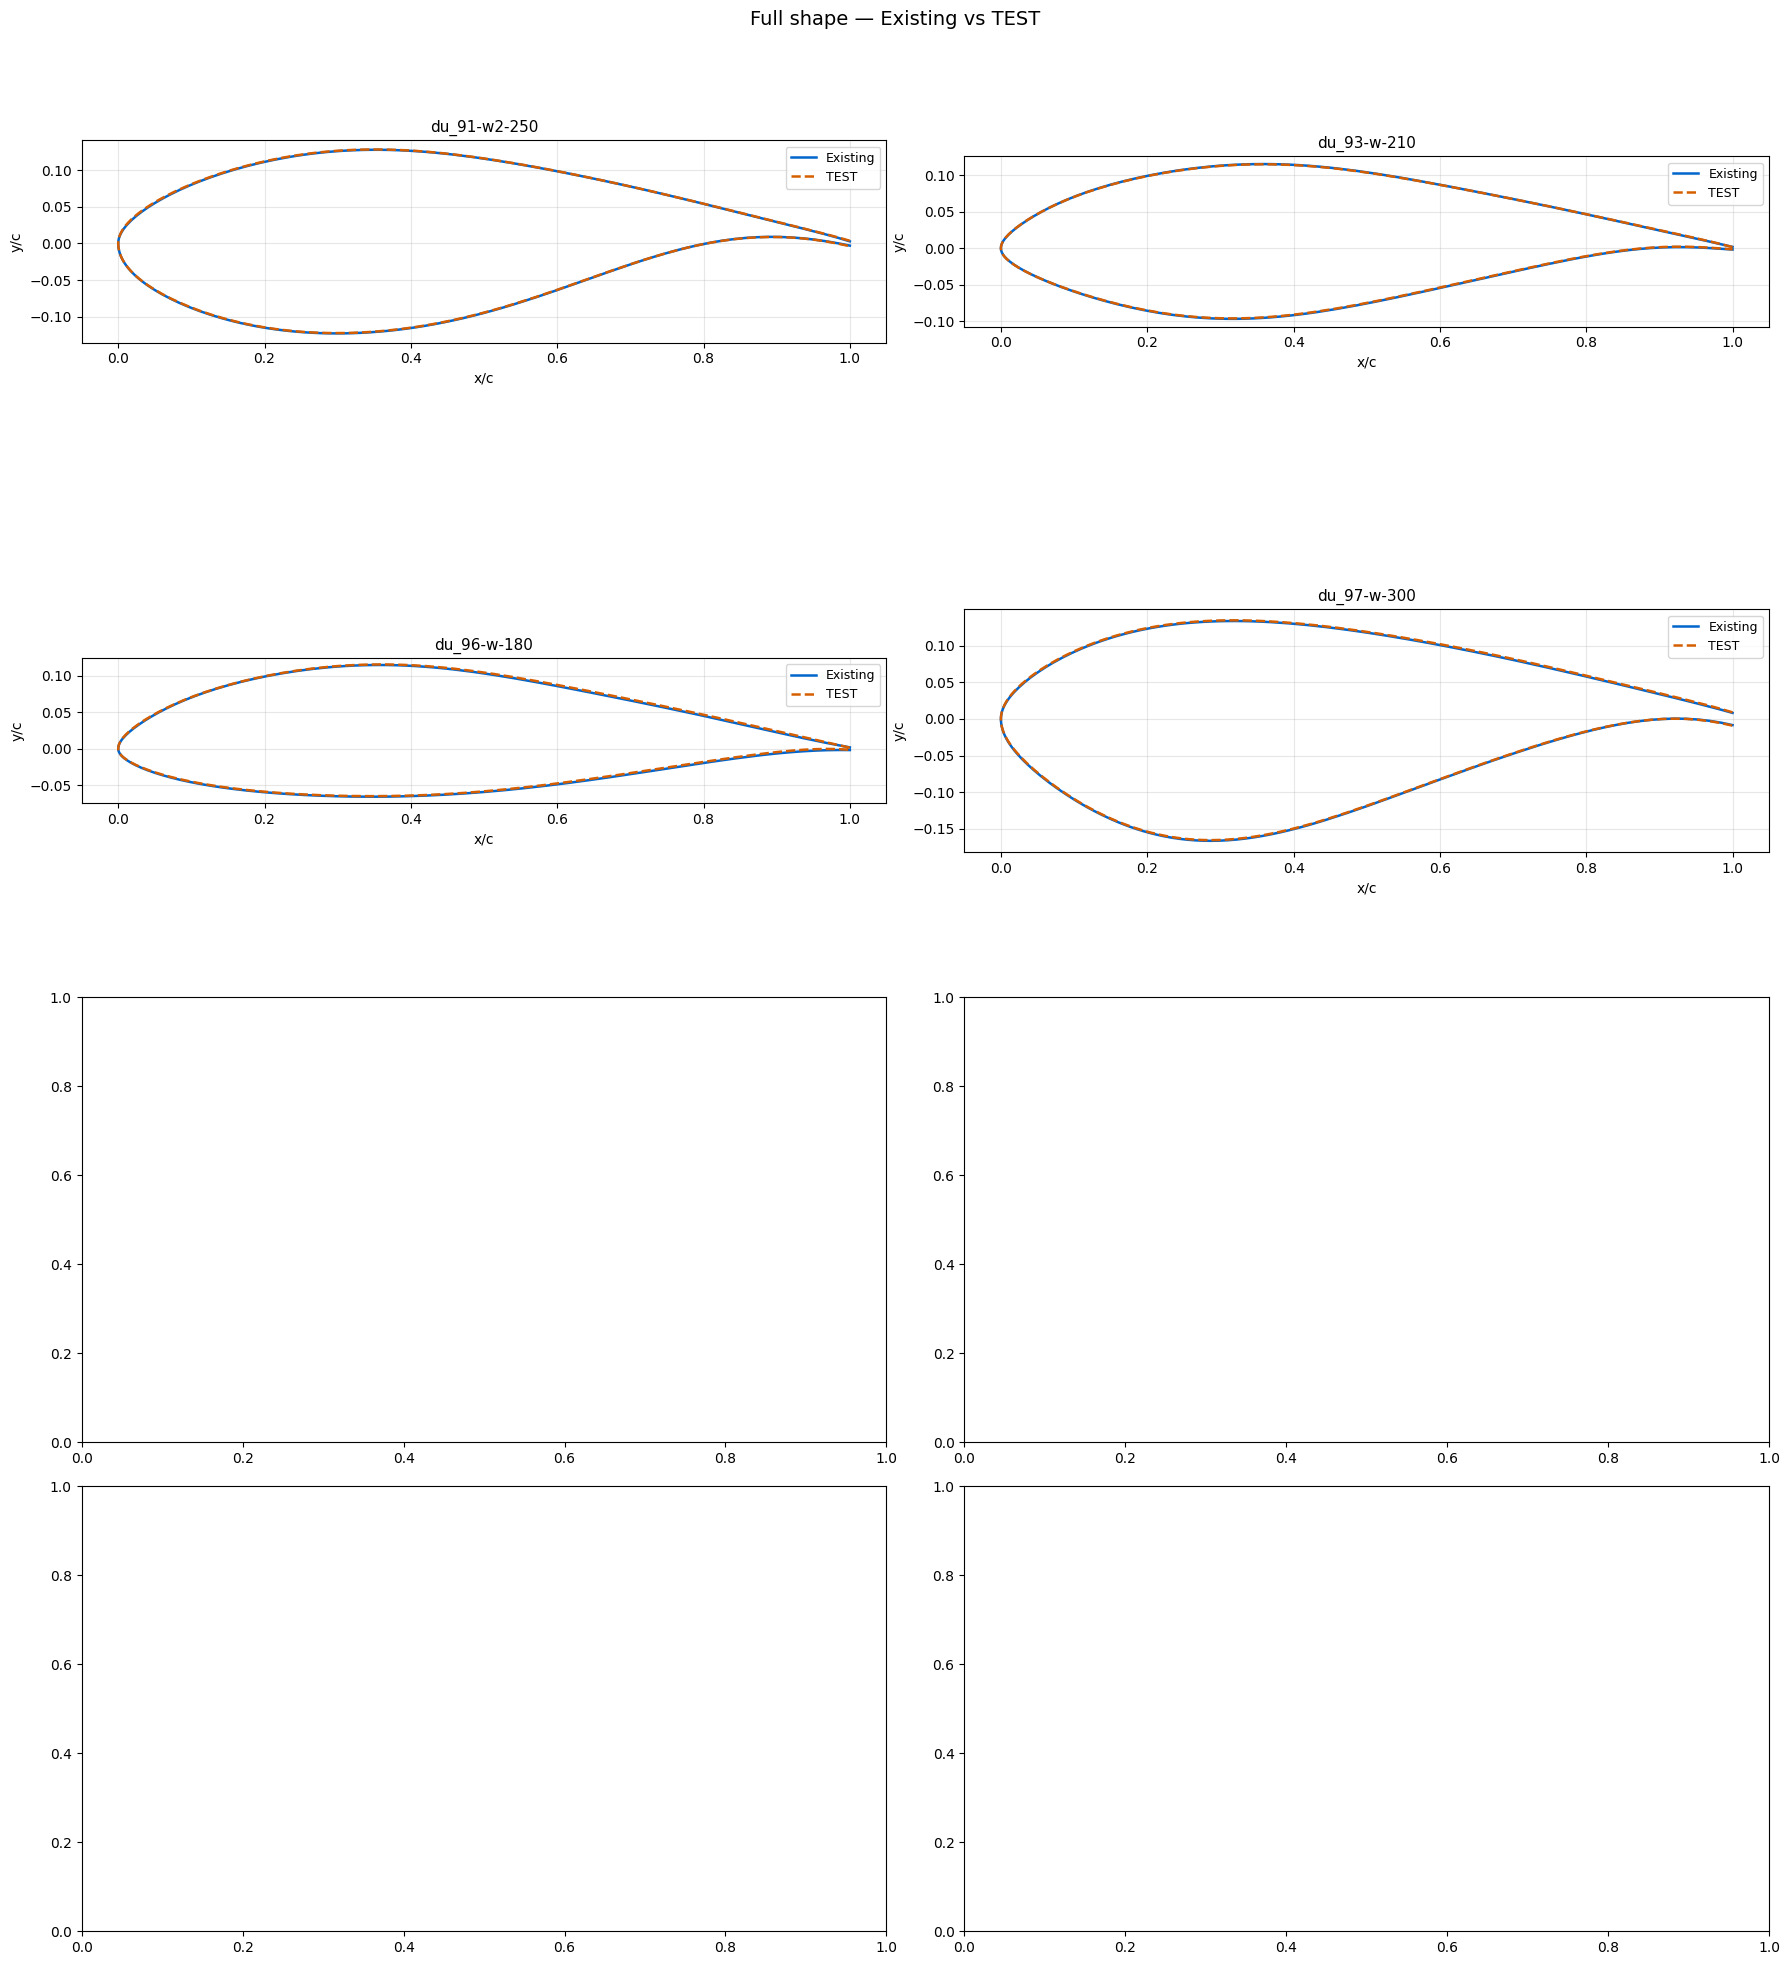

In [5]:
# Full airfoil shape overlay — 4×2 grid
fig, axes = plt.subplots(4, 2, figsize=(18, 20))
axes = axes.flatten()

for ax, r in zip(axes, records):
    ax.plot(r['x_e'], r['y_e'], '-',  color=dcc.blue, lw=1.8, label='Existing')
    ax.plot(r['x_t'], r['y_t'], '--', color=dcc.red,  lw=1.8, label='TEST')
    ax.set_title(r['name'], fontsize=11)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)
    ax.set_xlabel('x/c')
    ax.set_ylabel('y/c')

fig.suptitle('Full shape — Existing vs TEST', fontsize=14)
fig.tight_layout()
plt.show()


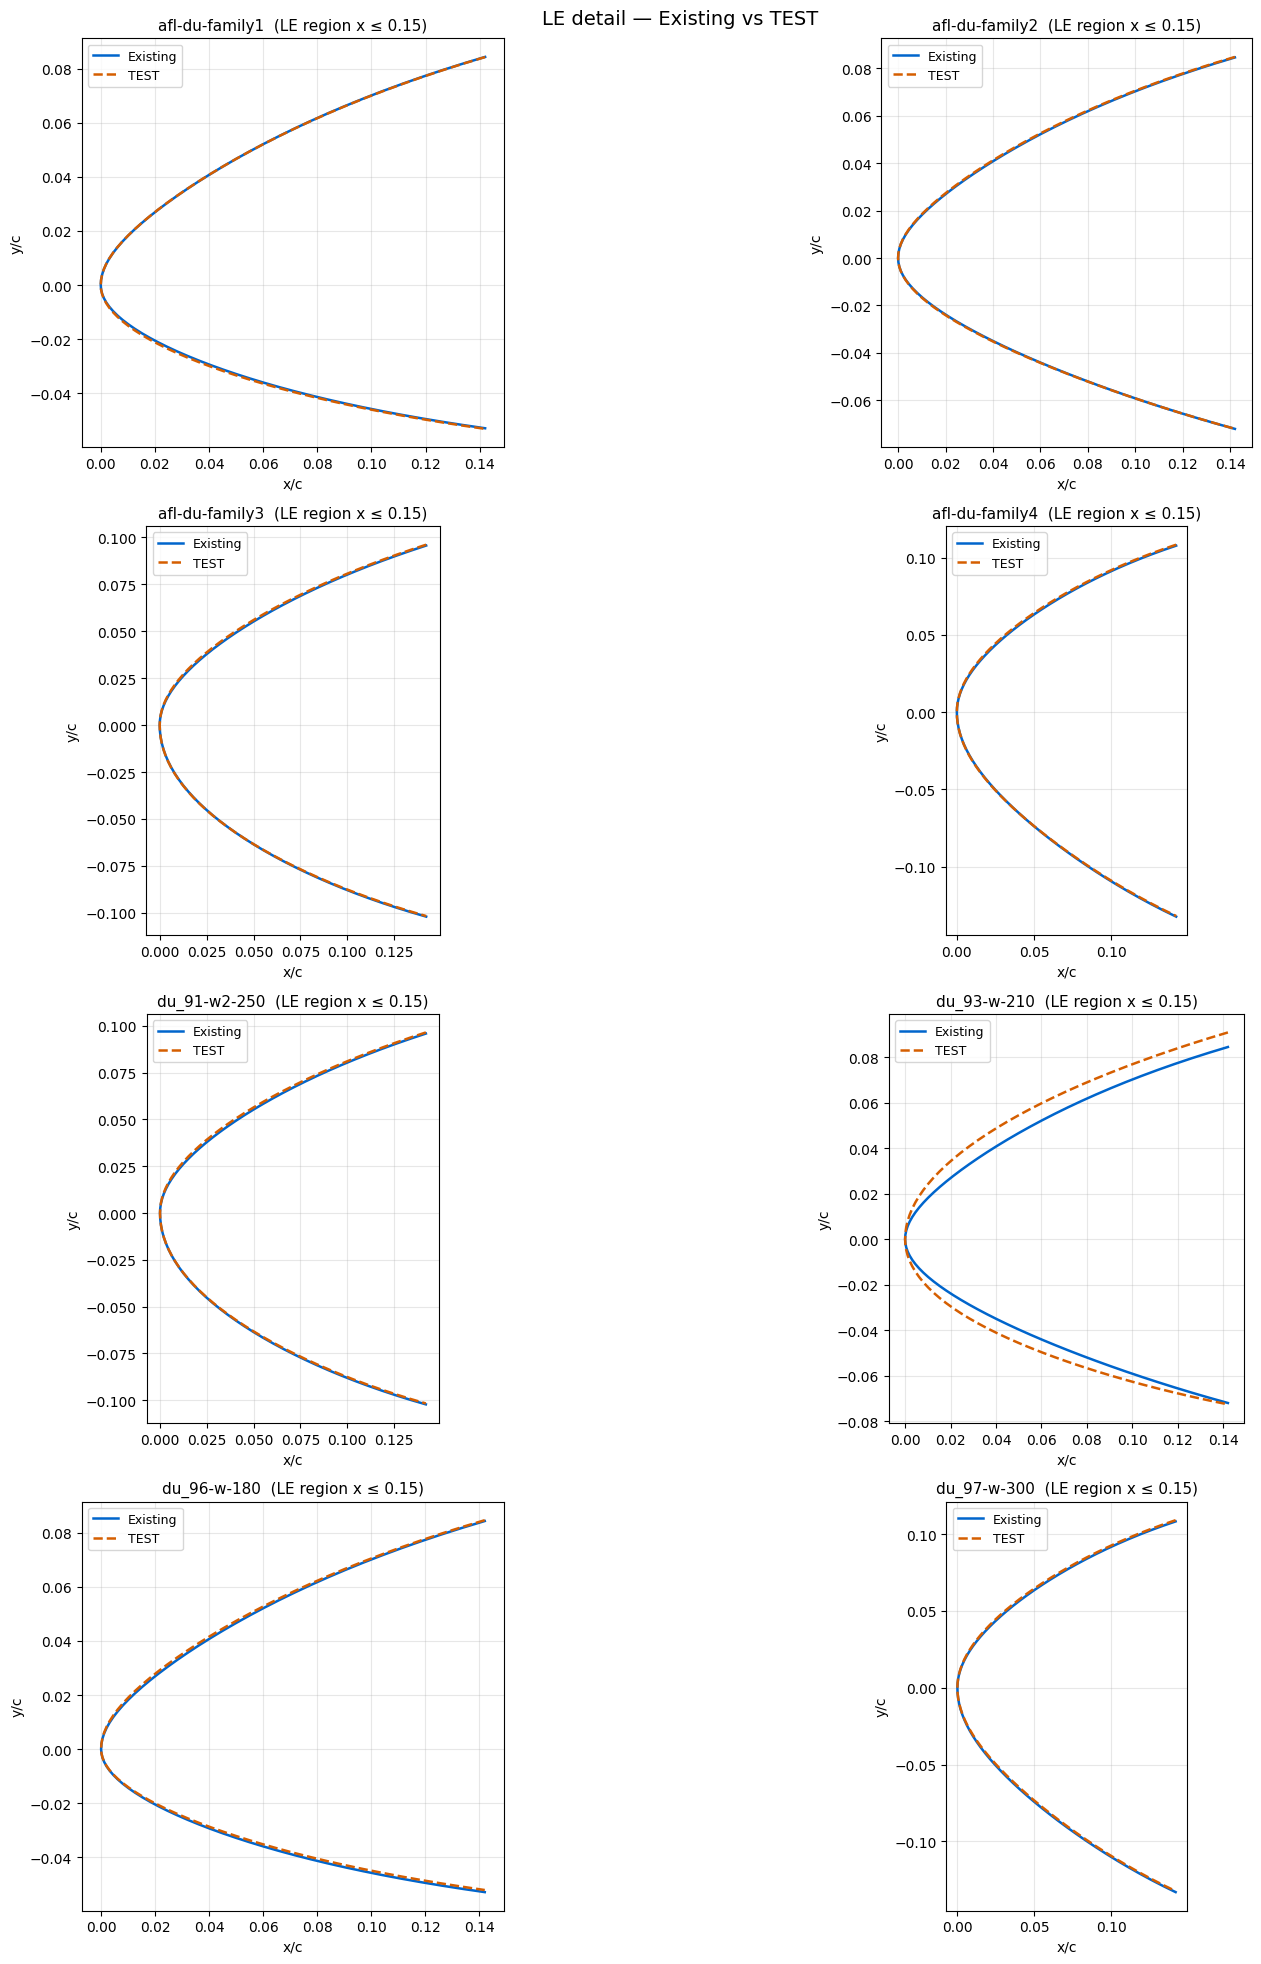

In [ ]:
# LE zoom (x ≤ 0.15)
fig, axes = plt.subplots(4, 2, figsize=(18, 20))
axes = axes.flatten()

for ax, r in zip(axes, records):
    mask_e = r['x_e'] <= 0.15
    mask_t = r['x_t'] <= 0.15
    ax.plot(r['x_e'][mask_e], r['y_e'][mask_e], '-',  color=dcc.blue, lw=1.8, label='Existing')
    ax.plot(r['x_t'][mask_t], r['y_t'][mask_t], '--', color=dcc.red,  lw=1.8, label='TEST')
    ax.set_title(r['name'] + '  (LE region x ≤ 0.15)', fontsize=11)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)
    ax.set_xlabel('x/c')
    ax.set_ylabel('y/c')

fig.suptitle('LE detail — Existing vs TEST', fontsize=14)
fig.tight_layout()
plt.show()


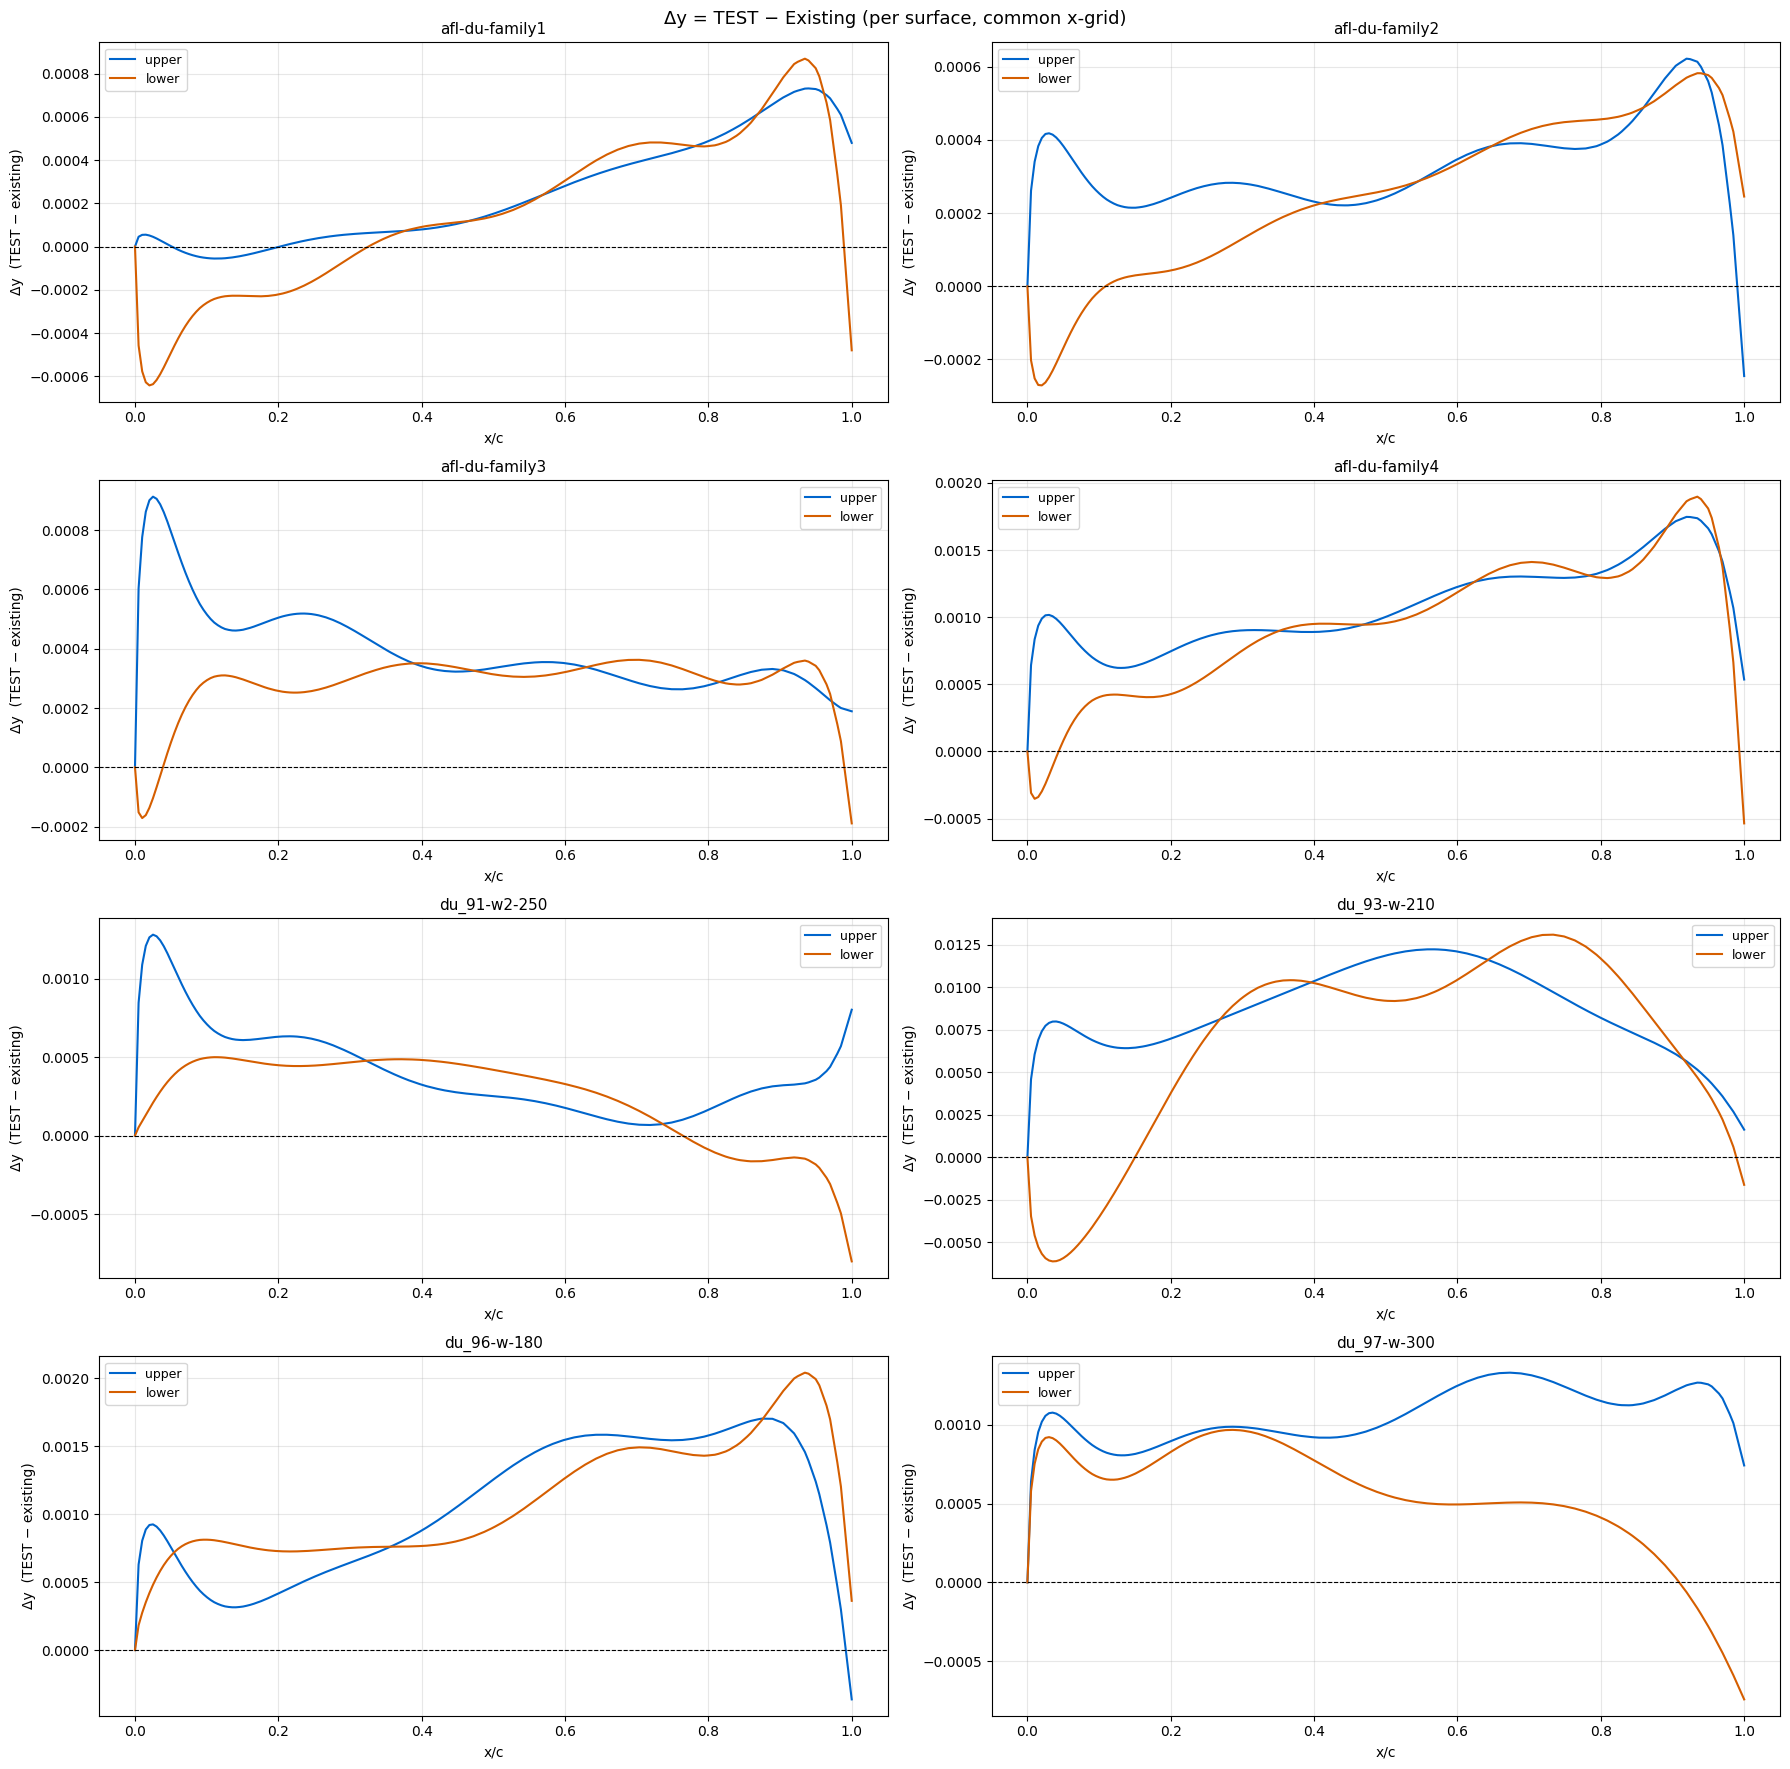

In [ ]:
# Δy vs x — upper and lower surfaces shown separately
fig, axes = plt.subplots(4, 2, figsize=(18, 18))
axes = axes.flatten()

for ax, r in zip(axes, records):
    ax.plot(r['x_grid'], r['delta_u'], color=dcc.blue,  lw=1.5, label='upper')
    ax.plot(r['x_grid'], r['delta_l'], color=dcc.red,   lw=1.5, label='lower')
    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.set_title(r['name'], fontsize=11)
    ax.set_xlabel('x/c')
    ax.set_ylabel('Δy  (TEST − existing)')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

fig.suptitle('Δy = TEST − Existing (per surface, common x-grid)', fontsize=13)
fig.tight_layout()
plt.show()
